<br>
<br>


# `#01: IoU: Intersection over union`

<br>
<br>

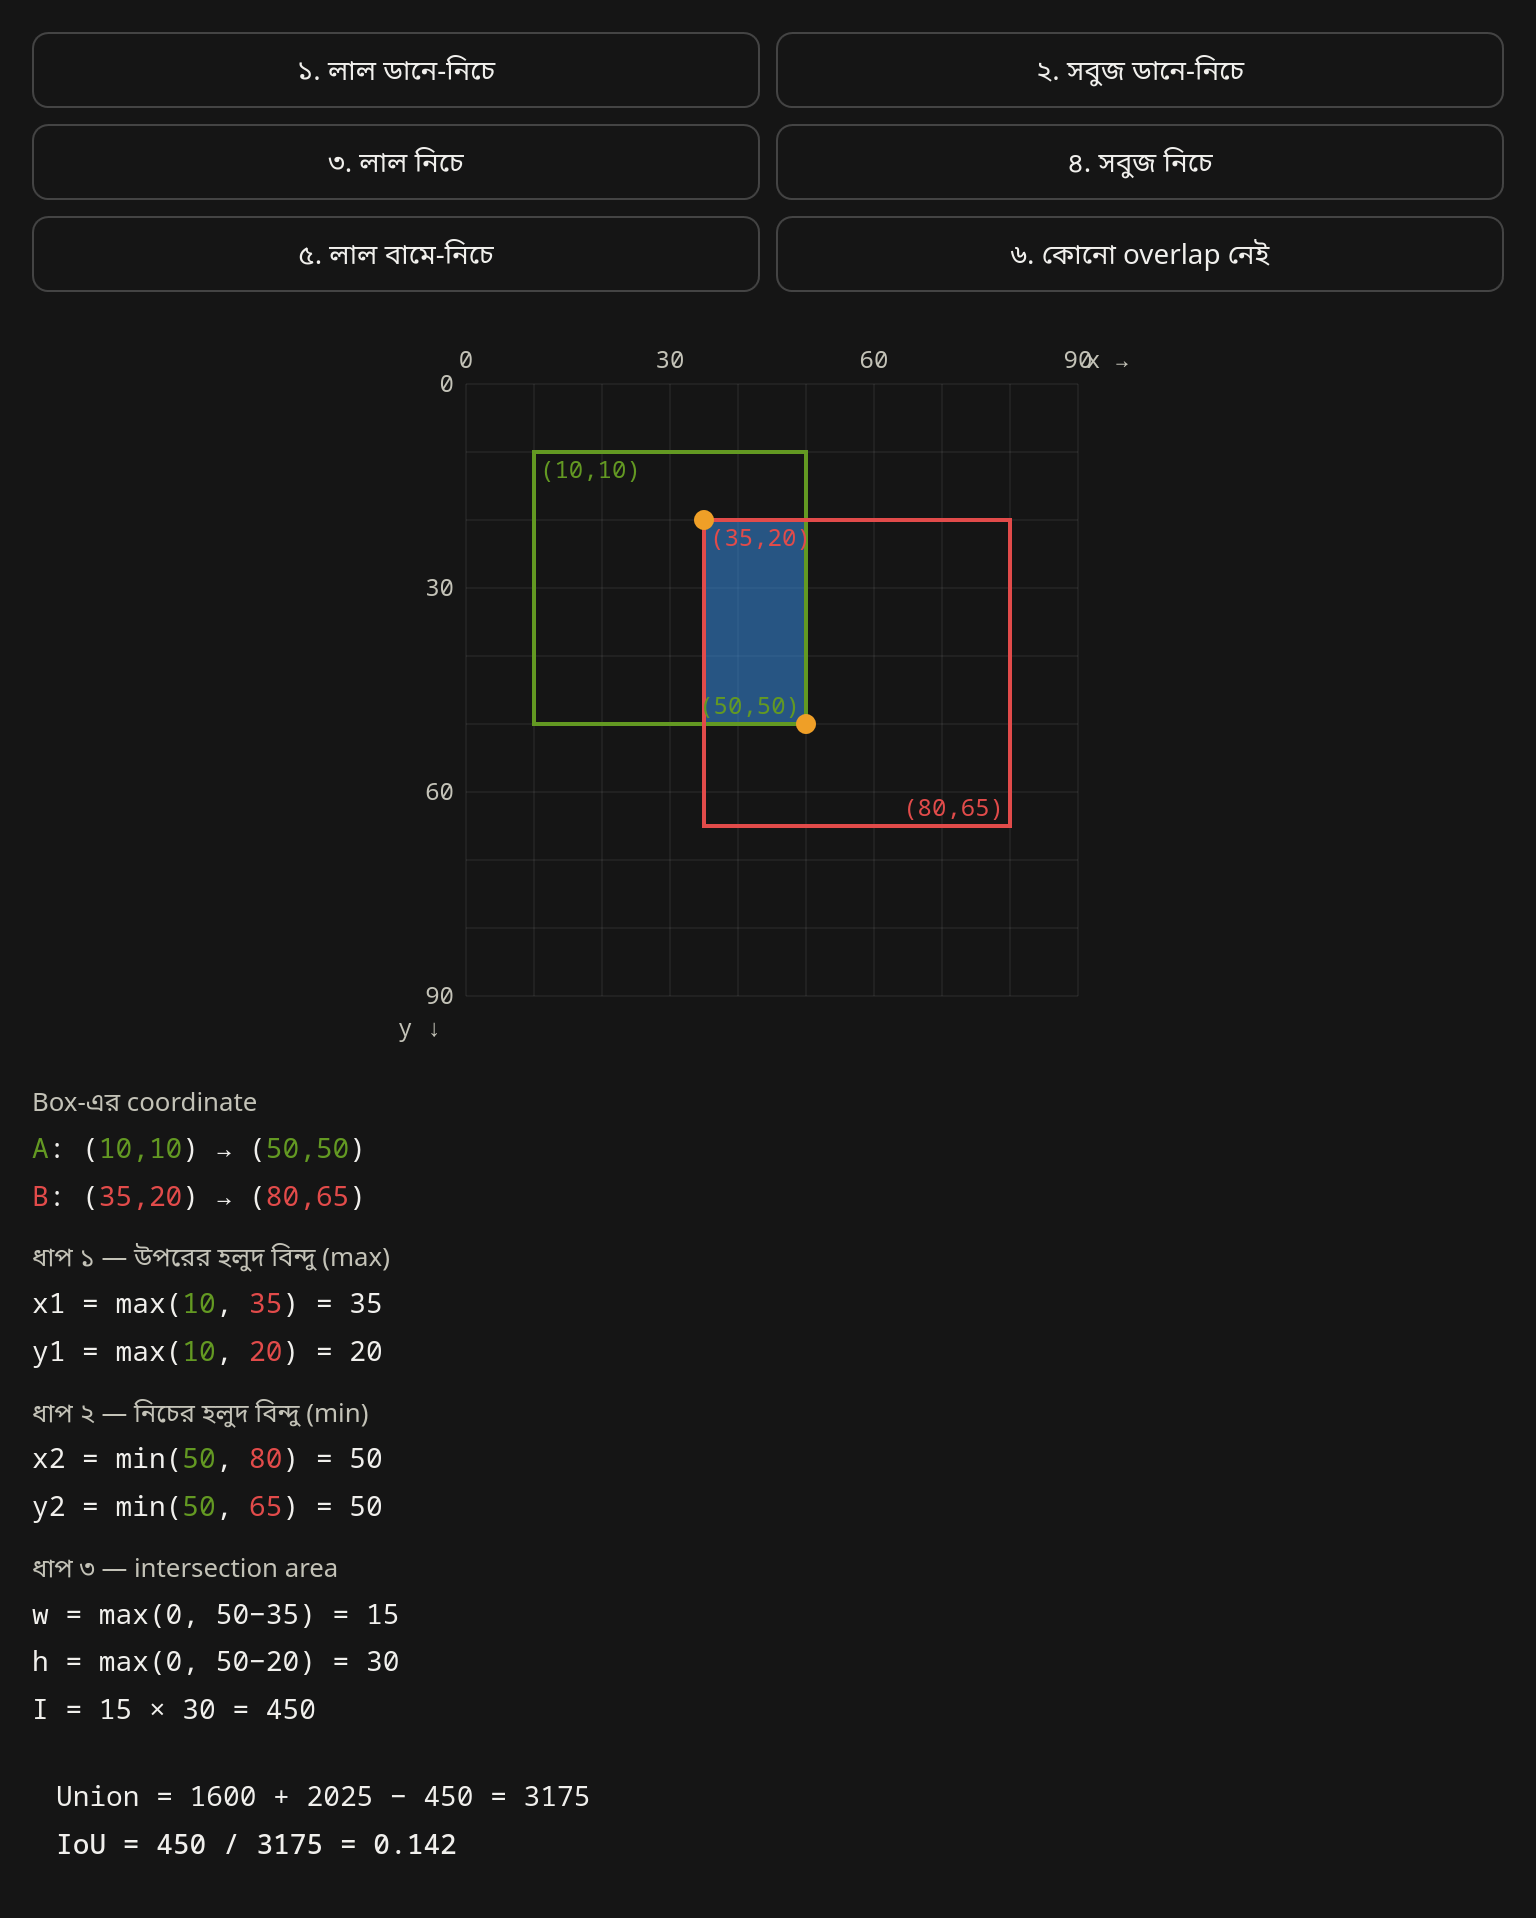

In [2]:

# Case:01
from IPython.display import Image
Image("../note/photo/image26.png")


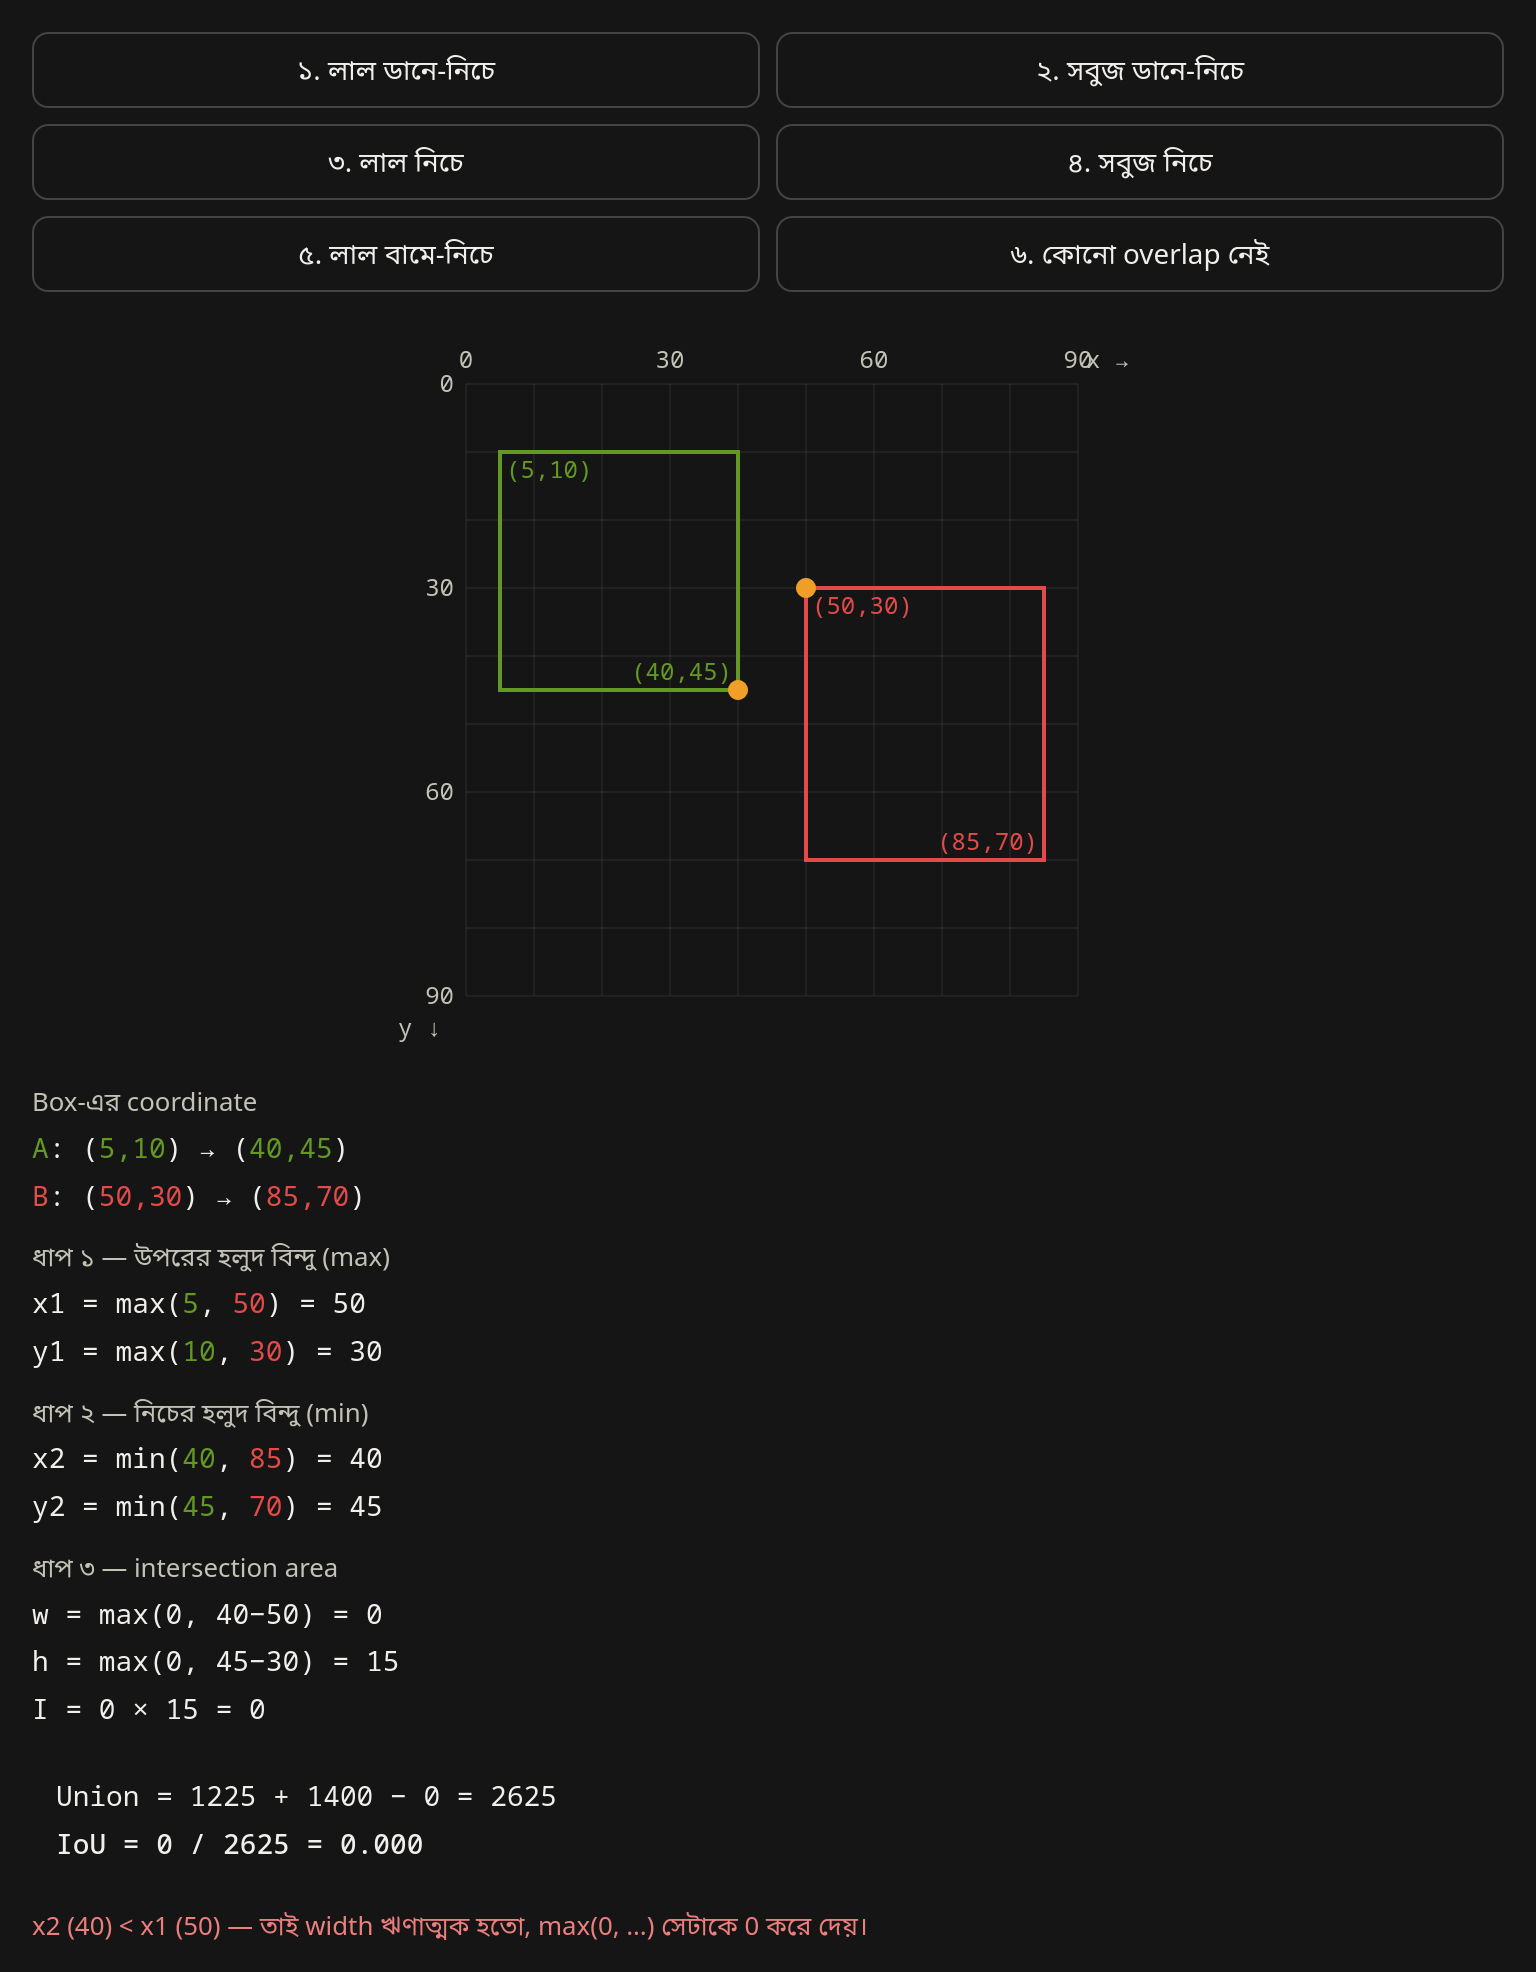

In [3]:
# Case:02
from IPython.display import Image
Image("../note/photo/image27.png")


In [4]:
import torch

# Input (shape [1,4],
box_a = torch.tensor([[10., 10., 50., 50.]])   # (x1,y1)=(10,10), (x2,y2)=(50,50)
box_b = torch.tensor([[35., 20., 80., 65.]])   # (x1,y1)=(35,20), (x2,y2)=(80,65)

print(box_a)
print(box_a.shape)
print(box_a.size(0))

print(box_a[:,2:].unsqueeze(1).expand(1,1,2))
innter = torch.tensor([[[15, 30]]])
innter[:,:,0]


tensor([[10., 10., 50., 50.]])
torch.Size([1, 4])
1
tensor([[[50., 50.]]])


tensor([[15]])

In [5]:

# implementation in pytorch:


def intersect(box_a, box_b):
    """ We resize both tensors to [A,B,2] without new malloc:
    [A,2] -> [A,1,2] -> [A,B,2]
    [B,2] -> [1,B,2] -> [A,B,2]
    Then we compute the area of intersect between box_a and box_b.
    Args:
      box_a: (tensor) bounding boxes, Shape: [A,4].
      box_b: (tensor) bounding boxes, Shape: [B,4].
    Return:
      (tensor) intersection area, Shape: [A,B].
    """
    # Input: A[[10,10,50,50]] B[[35,20,80,65]]->size(1,4)
    A = box_a.size(0) #1
    B = box_b.size(0) #1
    
    # torch.min -> [min(50,80), min(50,65)] = [[[50, 50]]]
    max_xy = torch.min(# [50,50] -> [[[50,50]]]  #(1,1,2) -> (pointA,pointB,total_2_point) -> 3D
                       box_a[:, 2:].unsqueeze(1).expand(A, B, 2),
                       box_b[:, 2:].unsqueeze(0).expand(A, B, 2))
    
    # torch.max -> [max(10,35), max(10,20)] = [[[35, 20]]]
    min_xy = torch.max( # [10,10] ->[[[10,10]]] # (1,1,2)
                       box_a[:, :2].unsqueeze(1).expand(A, B, 2),
                       box_b[:, :2].unsqueeze(0).expand(A, B, 2))
    
    # max_xy - min_xy = [50-35, 50-20] = [[[15, 30]]]
    # if any ans <0 then, that will be zero
    inter = torch.clamp((max_xy - min_xy), min=0)
    # [[15]]*[[30]] = [[450]] -> shape (1,1)
    return inter[:, :, 0] * inter[:, :, 1]


# orginal jaccard:
def box_iou_tensor(box_a, box_b):
    """Compute the box_iou_tensor overlap of two sets of boxes.  The box_iou_tensor overlap
    is simply the intersection over union of two boxes.  Here we operate on
    ground truth boxes and default boxes.
    E.g.:
        A ∩ B / A ∪ B = A ∩ B / (area(A) + area(B) - A ∩ B)
    Args:
        box_a: (tensor) Ground truth bounding boxes, Shape: [num_objects,4]
        box_b: (tensor) Prior boxes from priorbox layers, Shape: [num_priors,4]
    Return:
        box_iou_tensor overlap: (tensor) Shape: [box_a.size(0), box_b.size(0)]
    """
    inter = intersect(box_a, box_b)
    
    
    area_a = ((box_a[:, 2]-box_a[:, 0]) *
              (box_a[:, 3]-box_a[:, 1])).unsqueeze(1).expand_as(inter)  # [A,B]
    area_b = ((box_b[:, 2]-box_b[:, 0]) *
              (box_b[:, 3]-box_b[:, 1])).unsqueeze(0).expand_as(inter)  # [A,B]
    union = area_a + area_b - inter
    return inter / union  # [A,B]

# find IoU for pytorch: 
# Input (shape [1,4],
box_a = torch.tensor([[10., 10., 50., 50.]]) 
box_b = torch.tensor([[35., 20., 80., 65.]])  
box_iou_tensor(box_a,box_b)


tensor([[0.1417]])

In [7]:


#
# Implementatin in: numpy IoU
# import numpy as np:
#
import numpy as np 


# matrix_iou
def iou_numpy(a, b):
    """
    return iou of a and b, numpy version for data augenmentation
    """
    # a->[1,4] -> a[1,1,2] 
    # b->[1,4] -> b[1,2]
    lt = np.maximum(a[:, np.newaxis, :2], b[:, :2])
    rb = np.minimum(a[:, np.newaxis, 2:], b[:, 2:])

    # area of intersection:(1,1), axis=2 cause rb-lt(1,1,2)
    area_i = np.prod(rb - lt, axis=2) * (lt < rb).all(axis=2)
    
    # area of A(1,2) and B(1,2)
    area_a = np.prod(a[:, 2:] - a[:, :2], axis=1)
    area_b = np.prod(b[:, 2:] - b[:, :2], axis=1)
    
    # intersection/(A+B-intersection[1,1]
    return area_i / (area_a[:, np.newaxis] + area_b - area_i)


# Input (shape [1,4],
box_a = np.array([[10., 10., 50., 50.]])   
box_b = np.array([[35., 20., 80., 65.]])   


x = np.array([1, 2])    
# (2,) -> (2,1) 
x_new = x[:, np.newaxis]  
print("np.newaxis: add a new dimention:\n", x_new, x_new.shape)

iou_numpy(box_a,box_b)


np.newaxis: add a new dimention:
 [[1]
 [2]] (2, 1)


array([[0.14173228]])